### Import Libraries and Load Data ###

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import itertools

In [2]:
file_path = "final_data.csv"  
data = pd.read_csv(file_path)

In [3]:
# Parse the 'date' column and set as index
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data.set_index('date', inplace=True)

### Stationarity Test ###

In [4]:
from statsmodels.tsa.stattools import adfuller

In [4]:
target_variable = 'total energy consumption'

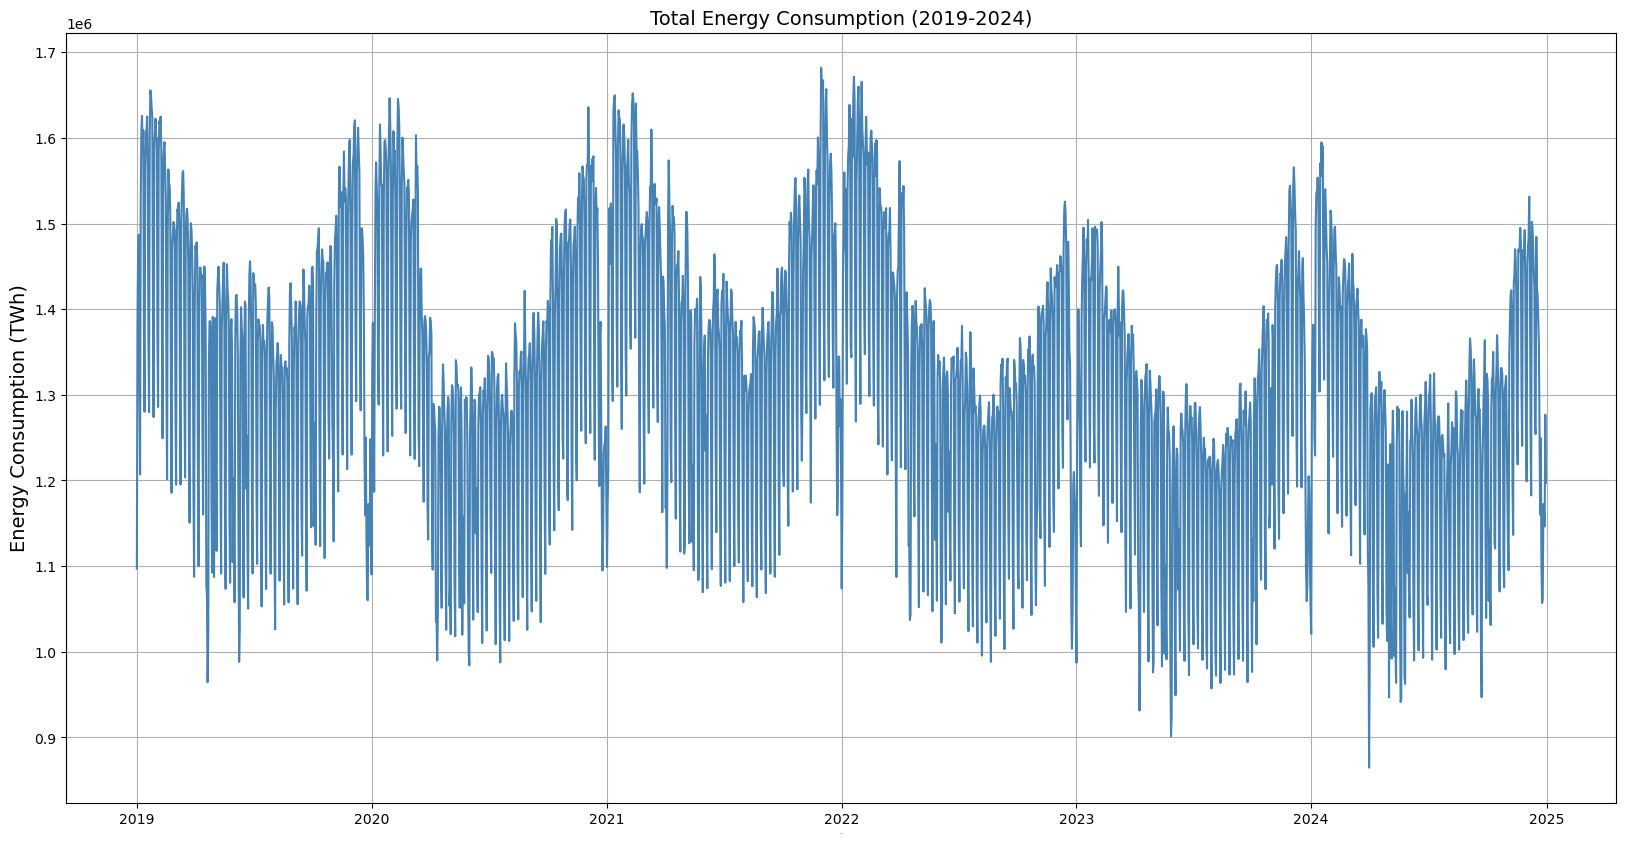

In [6]:
# Simple plot of total energy consumption 
plt.figure(figsize=(20, 10))
plt.plot(data[target_variable], label='Total Energy Consumption', color='steelblue')
plt.title('Total Energy Consumption (2019-2024)', fontsize=14)
plt.xlabel('Year', fontsize=1)
plt.ylabel('Energy Consumption (TWh)', fontsize=14)  # Adjust units as per your data
#plt.legend(loc='upper left', fontsize=14)
plt.grid(True)
#plt.tight_layout()
plt.show()

In [7]:
def test_stationarity(series, name="ADF Test"):
    adf_result = adfuller(series.dropna())
    print(f"\nADF Test for {name}")
    print(f"ADF Statistic: {adf_result[0]}")
    print(f"p-value: {adf_result[1]}")
    
    if adf_result[1] < 0.05:
        print("Result: The series is stationary (reject null hypothesis).")
    else:
        print("Result: The series is non-stationary (fail to reject null hypothesis).")
    
test_stationarity(data[target_variable], name=target_variable)


ADF Test for total energy consumption
ADF Statistic: -3.8872095006512124
p-value: 0.0021310208024995815
Result: The series is stationary (reject null hypothesis).


### Decompose the original Time Series and view all the components

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [9]:
result_decompose = seasonal_decompose(data[target_variable], model='additive') 

In [10]:
# Extract the components
trend = result_decompose.trend
seasonal = result_decompose.seasonal
residuals = result_decompose.resid

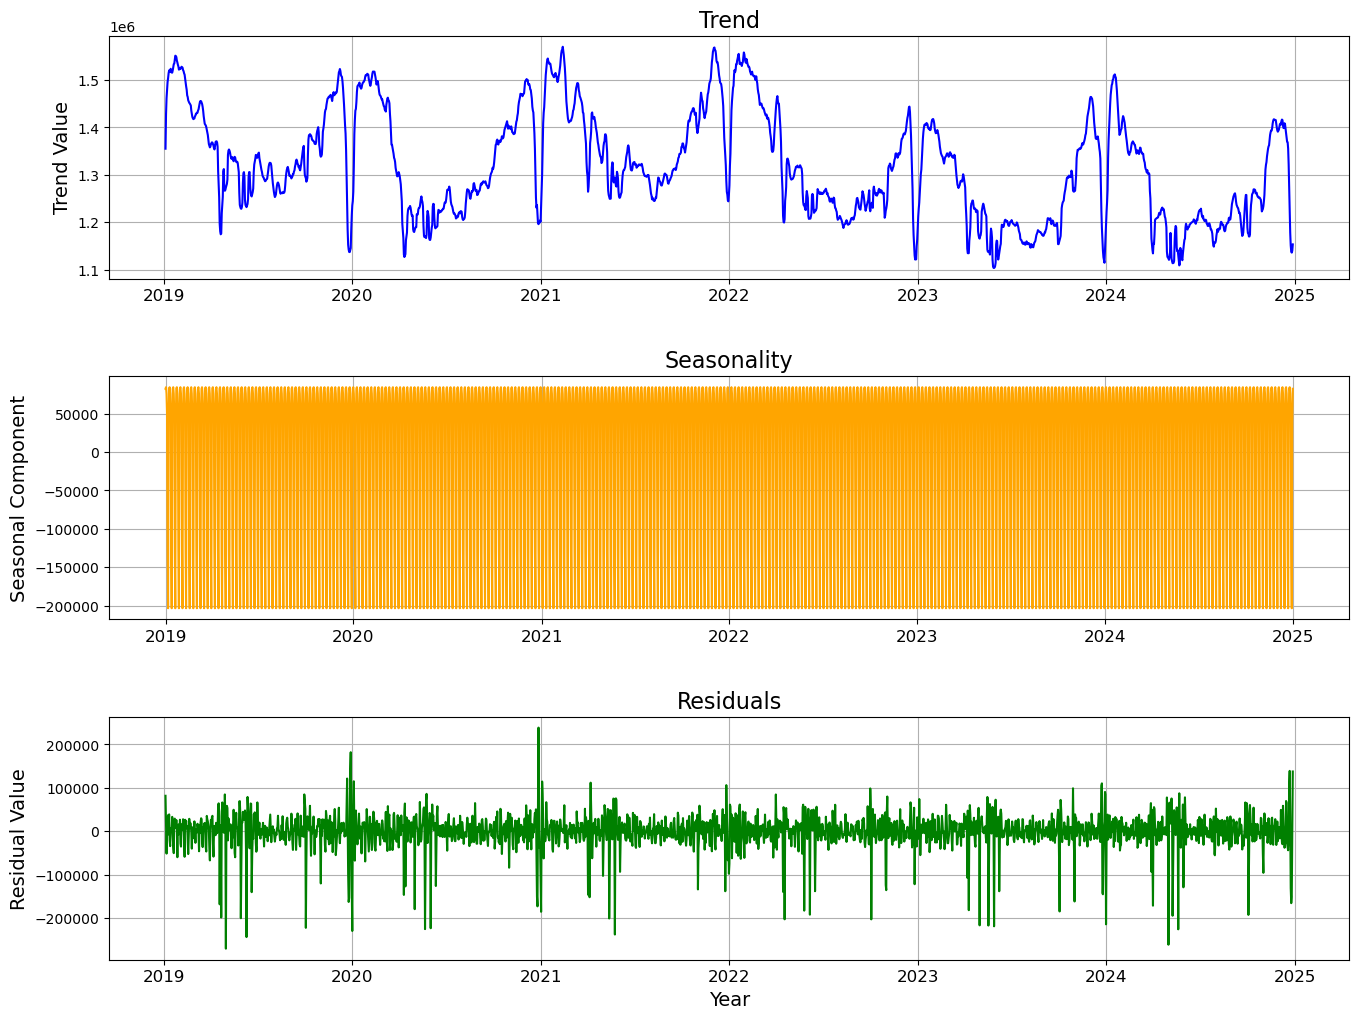

In [11]:
import matplotlib.pyplot as plt

# Create figure and adjust spacing
fig, axes = plt.subplots(3, 1, figsize=(16, 12))  # Share x-axis
fig.subplots_adjust(hspace=0.4)  # Increase space between subplots

# Plot trend
axes[0].plot(trend, color='blue')
axes[0].set_title('Trend', fontsize=16)
axes[0].set_ylabel('Trend Value', fontsize=14)
axes[0].grid()
axes[0].tick_params(axis='x', labelsize=12)  

# Plot seasonality
axes[1].plot(seasonal, color='orange')
axes[1].set_title('Seasonality', fontsize=16)
axes[1].set_ylabel('Seasonal Component', fontsize=14)
axes[1].grid()
axes[1].tick_params(axis='x', labelsize=12)  # Apply to second subplot

# Plot residuals
axes[2].plot(residuals, color='green')
axes[2].set_title('Residuals', fontsize=16)
axes[2].set_xlabel('Year', fontsize=14)  # Set x-axis label on last subplot
axes[2].set_ylabel('Residual Value', fontsize=14)
axes[2].grid()
axes[2].tick_params(axis='x', labelsize=12)  # Apply to third subplot

plt.savefig("plots_energy/05_energy_seasonality.png", dpi=150, bbox_inches='tight')
plt.show()

#### Plot ACF and PACF 

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [13]:
# define function that returns the ACF and PACF plots for a given time series
def autocorrelation_plots(timeseries, n_lags, fontsize=14, save_as=None):
    plt.figure(figsize=(15,5))
    plt.subplot(121)
    plot_acf(data[target_variable], ax=plt.gca(), lags=n_lags)
    plt.title('Autocorrelation', fontsize=14)
    plt.xlabel('Number of lags', fontsize=14)
    plt.ylabel('correlation', fontsize=14)
    
    plt.subplot(122)
    plot_pacf(data[target_variable], ax=plt.gca(), lags=n_lags)
    plt.title('Partial Autocorrelation', fontsize=14)
    plt.xlabel('Number of lags', fontsize=14)
    plt.ylabel('correlation', fontsize=14)
    
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
        
    plt.show()

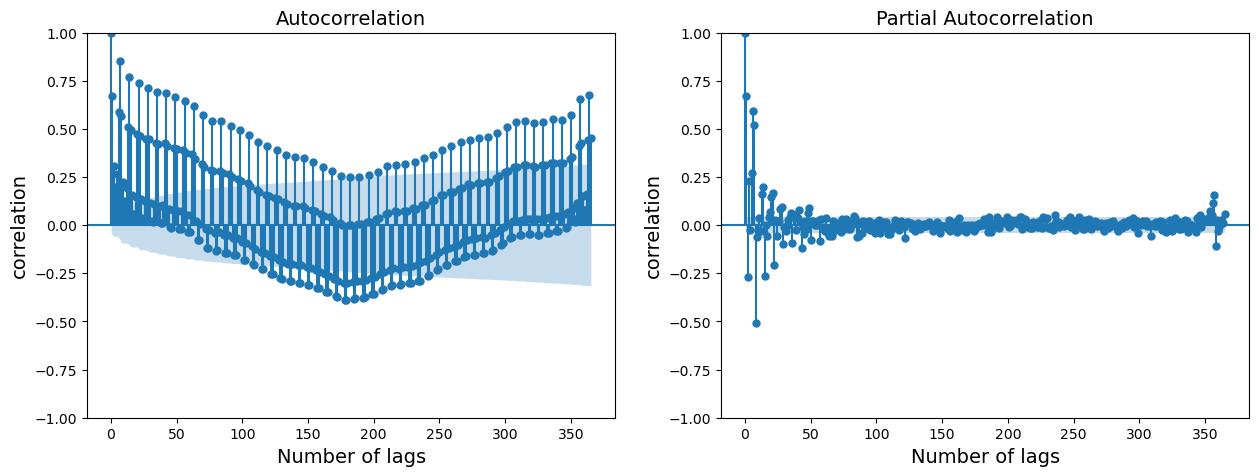

In [14]:
autocorrelation_plots(data[target_variable], 365, save_as="plots_energy/acf_pacf_365.png")

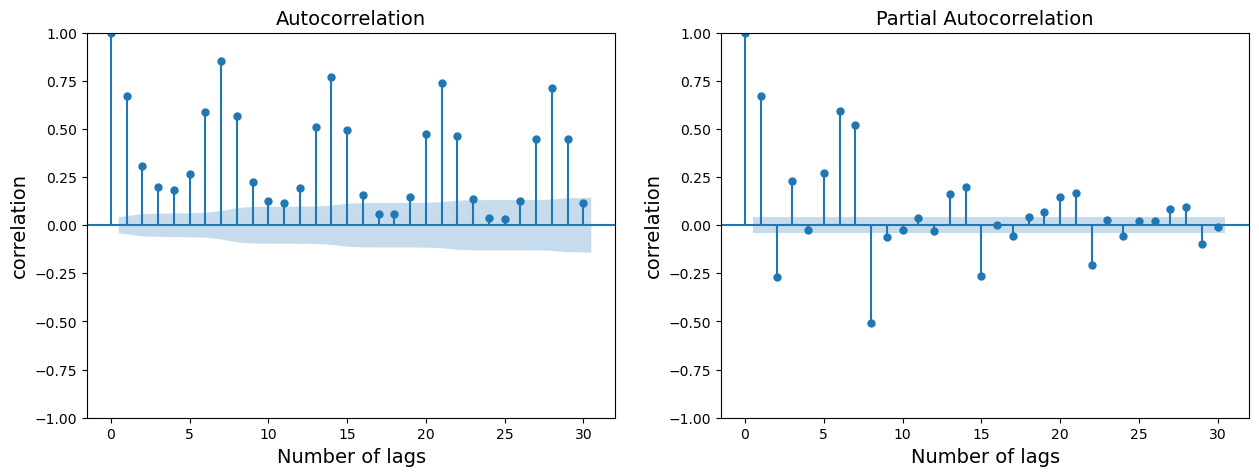

In [15]:
autocorrelation_plots(data[target_variable], 30, save_as="plots_energy/acf_pacf_30.png")

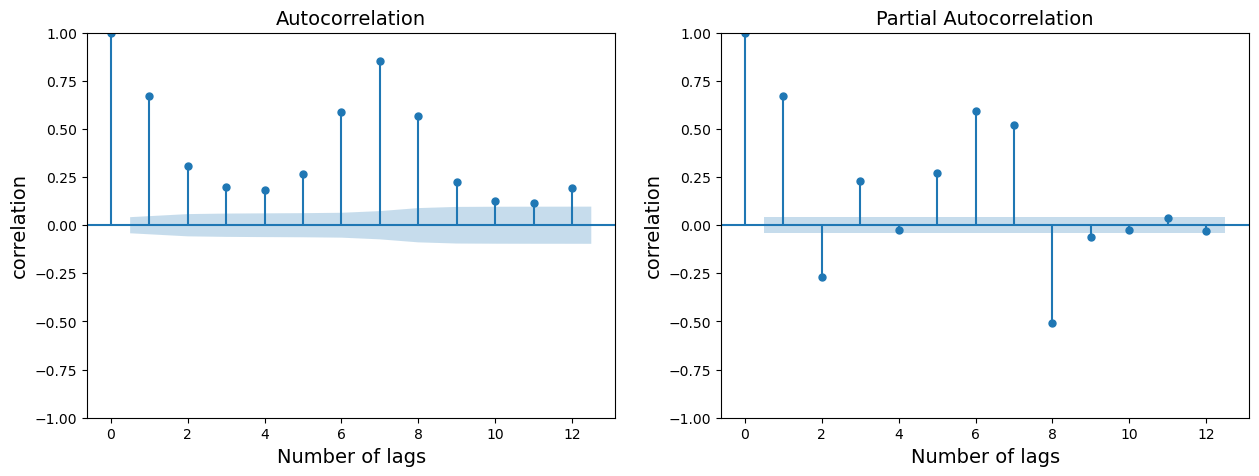

In [16]:
autocorrelation_plots(data[target_variable], 12, save_as="plots_energy/acf_pacf_12.png")

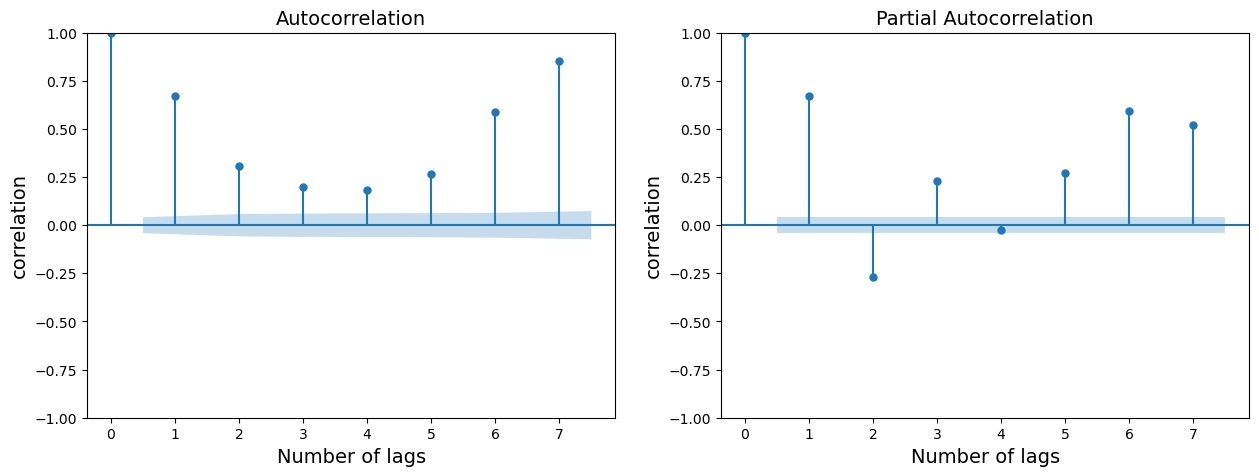

In [17]:
autocorrelation_plots(data[target_variable], 7, save_as="plots_energy/acf_pacf_7.png")

### Split train-test data

In [5]:
import pandas as pd

In [6]:
file_path = "final_data.csv"  
data = pd.read_csv(file_path)

In [20]:
# Convert 'date' column to datetime, auto-detecting the format
data['date'] = pd.to_datetime(data['date'], errors='coerce')

In [21]:
# Set the 'date' column as the index for easy slicing
data.set_index('date', inplace=True)

In [22]:
# Split the dataset
train_data = data.loc['2019-01-01':'2023-12-31']  # Train set
test_data = data.loc['2024-01-01':'2024-12-31']   # Test set

In [23]:
train_data.to_csv("train_data.csv", index=True)
test_data.to_csv("test_data.csv", index=True)

### Determine Seasonality Order

In [7]:
from pmdarima import auto_arima
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
target_variable = 'total energy consumption'

In [9]:
train_data = pd.read_csv("train_data.csv", index_col="date", parse_dates=True)
test_data = pd.read_csv("test_data.csv", index_col="date", parse_dates=True)

In [10]:
# Extract the target variable
y_train = train_data[target_variable]
y_test = test_data[target_variable]

In [ ]:
'''auto_model = auto_arima(
    y_train,
    seasonal=True,
    m=12,  # Monthly seasonality
    stepwise=True,
    suppress_warnings=True,
    max_order=None,
)
print(auto_model.summary())'''

In [11]:
# Define the orders for SARIMAX
order = (2, 1, 1)  #  differencing (p,d,q)
seasonal_order = (1, 0, 2, 12)  # Seasonal differencing (P, D, Q, m)

In [12]:
# Fit SARIMAX model
sarimax_model = SARIMAX(
    y_train,  
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [13]:
# Fit the model
fitted_model = sarimax_model.fit(disp=False)

In [14]:
print(fitted_model.summary())

                                        SARIMAX Results                                        
Dep. Variable:                total energy consumption   No. Observations:                 1826
Model:             SARIMAX(2, 1, 1)x(1, 0, [1, 2], 12)   Log Likelihood              -23258.308
Date:                                 Fri, 14 Feb 2025   AIC                          46530.615
Time:                                         21:09:41   BIC                          46569.080
Sample:                                     01-01-2019   HQIC                         46544.815
                                          - 12-31-2023                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5018      0.044     11.511      0.000       0.416       0

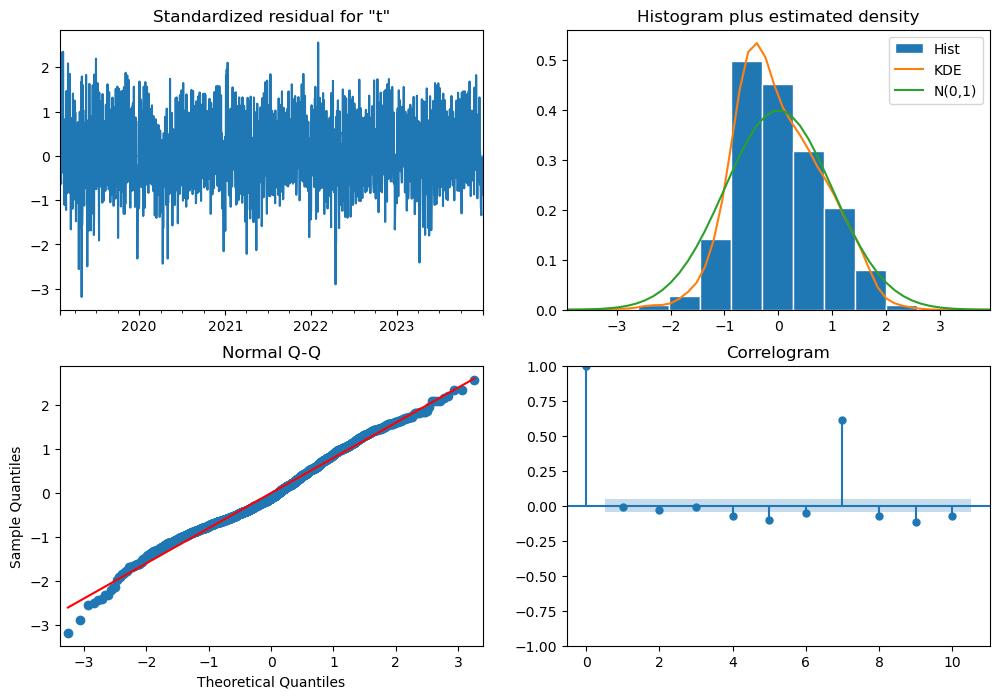

In [15]:
# Plot diagnostics to check model assumptions
fitted_model.plot_diagnostics(figsize=(12, 8))
plt.show()

In [16]:
# Make predictions on the test set
y_pred = fitted_model.forecast(steps=len(y_test))  # Predict the test data

In [17]:
# Calculate MAE and RMSE
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

In [18]:
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 117758.21442321448
Root Mean Squared Error (RMSE): 150958.06247522467


In [19]:
# Forecast for the test period
forecast_steps = len(y_test)
forecast = fitted_model.get_forecast(steps=forecast_steps)
forecast_index = y_test.index
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

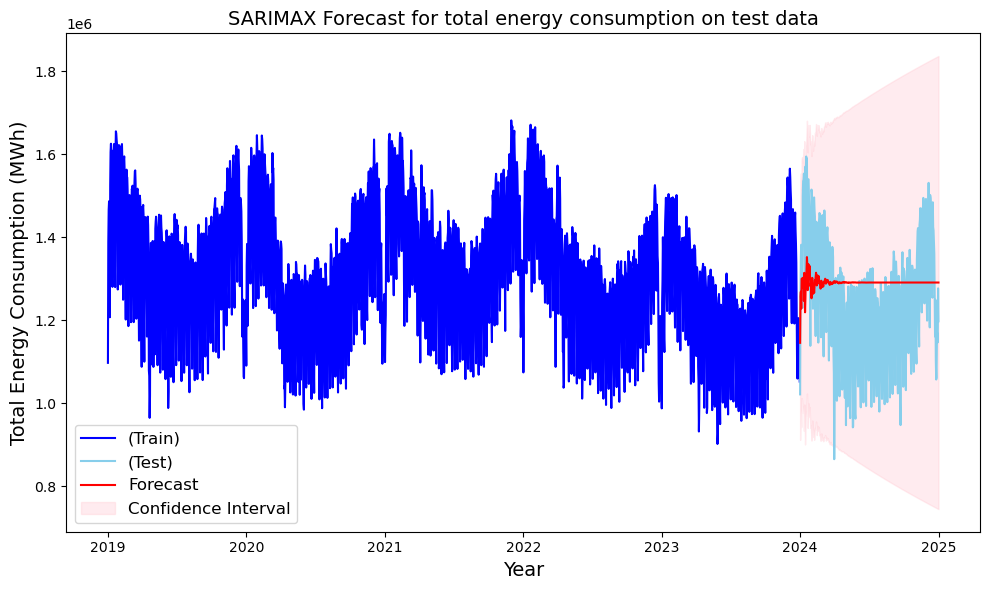

In [23]:
# Plot train data, test data, and forecast
plt.figure(figsize=(10, 6))
# Plot the train data
plt.plot(y_train.index, y_train, label="(Train)", color="blue")

# Plot the test data (actual values)
plt.plot(y_test.index, y_test, label="(Test)", color="skyblue")

# Plot the forecast
plt.plot(y_test.index, forecast_mean, label="Forecast", color="red")

# Plot the confidence intervals
plt.fill_between(
    y_test.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    color="pink",
    alpha=0.3,
    label="Confidence Interval"
)

# Add title and labels
plt.title("SARIMAX Forecast for total energy consumption on test data", fontsize=14)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Total Energy Consumption (MWh)", fontsize=14)
plt.legend(loc='lower left', fontsize=12)
plt.tight_layout()
plt.savefig("plots_energy/sarimax_energy_forecast_on_test_data.png", bbox_inches='tight')
plt.show()

### SARIMAX with auxiliary variables

In [24]:
auxiliary_variables = [
    'gdp', 'prices', 'Mean_Temperature',  'nuclear', 'other renewables'
]

In [25]:
exog_train = train_data[auxiliary_variables]
exog_test = test_data[auxiliary_variables]

In [26]:
# Fit SARIMAX with auxiliary variables
sarimax_with_exog = SARIMAX(
    y_train,
    exog=exog_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [27]:
print(sarimax_with_exog.summary())

                                        SARIMAX Results                                        
Dep. Variable:                total energy consumption   No. Observations:                 1826
Model:             SARIMAX(2, 1, 1)x(1, 0, [1, 2], 12)   Log Likelihood              -20048.848
Date:                                 Fri, 14 Feb 2025   AIC                          40121.697
Time:                                         21:17:55   BIC                          40187.636
Sample:                                     01-01-2019   HQIC                         40146.038
                                          - 12-31-2023                                         
Covariance Type:                                   opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
gdp                125.2194      0.300    417.117      0.000  

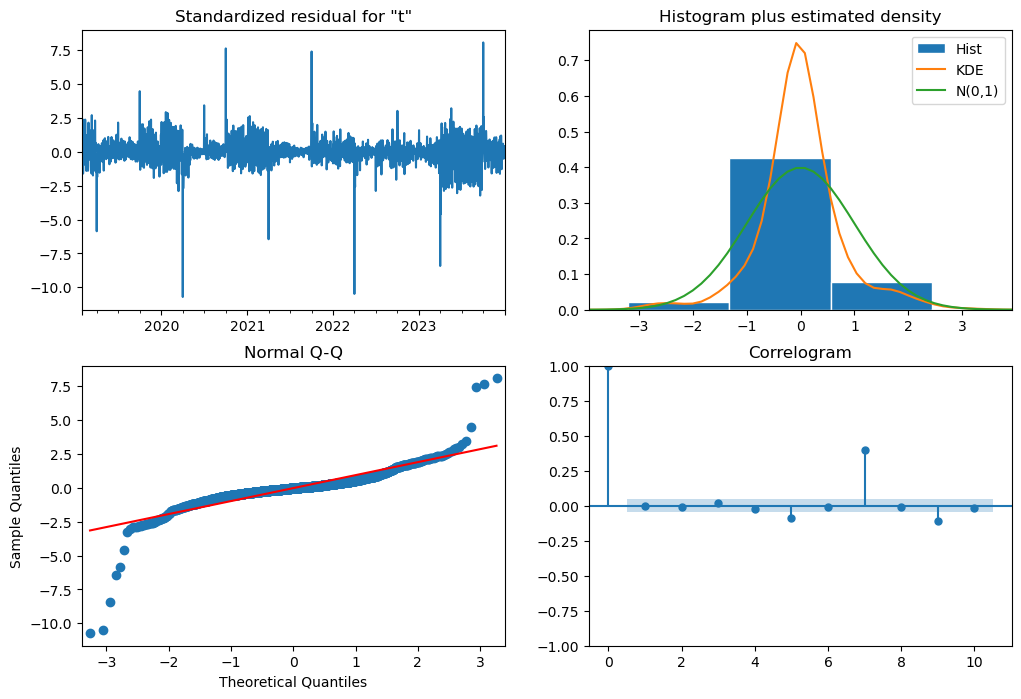

In [28]:
# Plot diagnostics to check model assumptions
sarimax_with_exog.plot_diagnostics(figsize=(12, 8))
plt.show()

In [29]:
# Forecast on the test set with confidence intervals
forecast_results = sarimax_with_exog.get_forecast(steps=len(exog_test), exog=exog_test)
y_pred = forecast_results.predicted_mean
confidence_intervals = forecast_results.conf_int()

In [30]:
# Extract lower and upper bounds for the confidence interval
lower_bound = confidence_intervals.iloc[:, 0]
upper_bound = confidence_intervals.iloc[:, 1]

In [31]:
# Calculate MAE and RMSE
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 87918.2550661622
Root Mean Squared Error (RMSE): 112569.44592617608


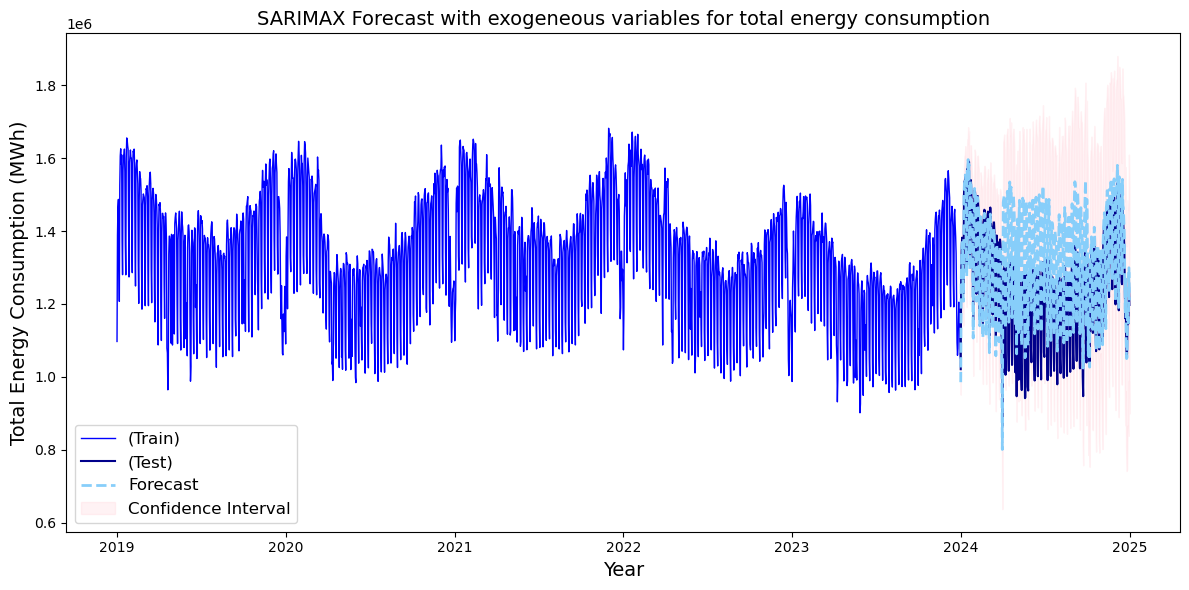

In [129]:
# Plot the forecast vs actuals with confidence intervals
plt.figure(figsize=(12, 6))

# Plot actual train data
plt.plot(train_data.index, y_train, label='(Train)', color='blue', linewidth=1)

# Plot actual test data
plt.plot(test_data.index, y_test, label='(Test)', color='darkblue', linewidth=1.5)

# Plot forecasted values
plt.plot(test_data.index, y_pred, label='Forecast', color='lightskyblue', linewidth=2, linestyle='--')

# Add confidence intervals with reduced opacity
plt.fill_between(test_data.index, lower_bound, upper_bound, color='pink', alpha=0.2, label='Confidence Interval')

# Add title, labels, and legend
plt.title(f'SARIMAX Forecast with exogeneous variables for {target_variable}', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Total Energy Consumption (MWh)', fontsize=14)
plt.legend(loc='lower left', fontsize=12)

# Display the plot
plt.tight_layout()
plt.savefig("plots_energy/sarimax_energy_forecast_with_aux.png", bbox_inches='tight')
plt.show()

### Train SARIMAX model on the entire dataset

In [100]:
# Fit SARIMAX on the entire dataset
final_model = SARIMAX(
    data[target_variable],  # Use the target variable dynamically
    exog=data[auxiliary_variables],  # Use auxiliary variables dynamically
    order=order,  # Use the determined order
    seasonal_order=seasonal_order,  # Use the determined seasonal order
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)
print("Final SARIMAX model trained on the entire dataset.")

C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Final SARIMAX model trained on the entire dataset.


In [101]:
# Print model summary
print(final_model.summary())

                                        SARIMAX Results                                        
Dep. Variable:                total energy consumption   No. Observations:                 2192
Model:             SARIMAX(2, 1, 1)x(1, 0, [1, 2], 12)   Log Likelihood              -24223.594
Date:                                 Fri, 14 Feb 2025   AIC                          48471.188
Time:                                         22:05:36   BIC                          48539.350
Sample:                                     01-01-2019   HQIC                         48496.115
                                          - 12-31-2024                                         
Covariance Type:                                   opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
gdp                120.8950      0.285    424.863      0.000  

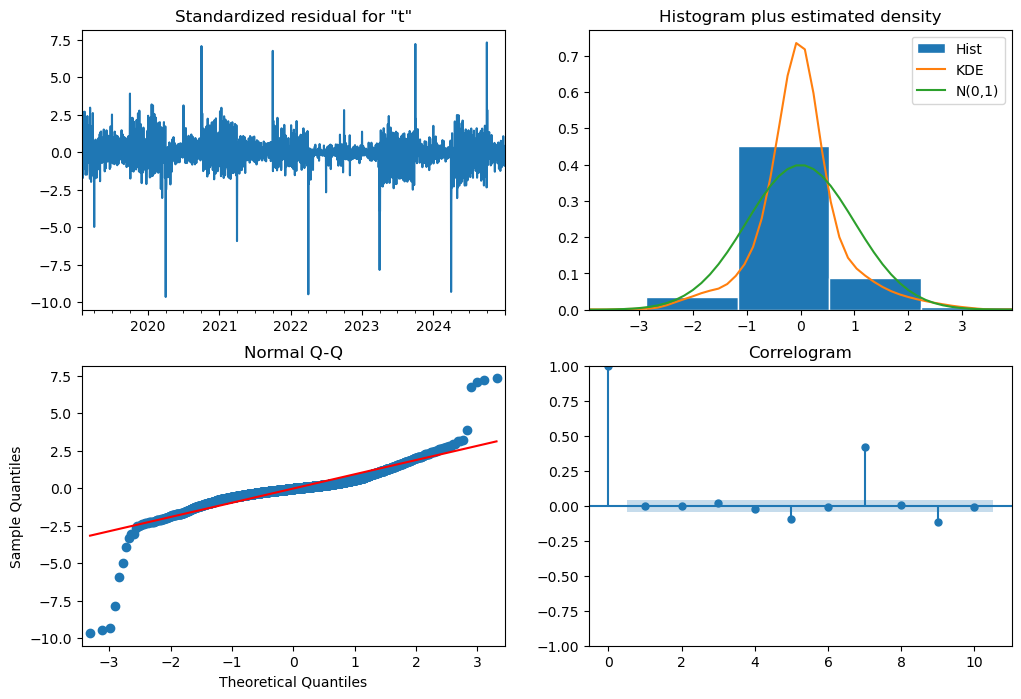

In [102]:
# Plot diagnostics to check model assumptions
final_model.plot_diagnostics(figsize=(12, 8))
plt.show()

For SARIMAX Model, the only requirement to use an exogenous variable is that, we should know the value of the variable during the forecast period as well.

In [103]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

In [104]:
file_path = "final_data.csv"  
data = pd.read_csv(file_path)

# Parse the 'date' column and set as index
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data.set_index('date', inplace=True)

In [105]:
# Decompose each auxiliary variable to extract trends and seasonality
forecast_days = pd.date_range('2025-01-01', '2026-12-31', freq='D')
projected_aux_vars = pd.DataFrame({'date': forecast_days})
projected_aux_vars.set_index('date', inplace=True)

In [106]:
for aux_var in auxiliary_variables:
    # Decompose the auxiliary variable (last 3 years)
    result = seasonal_decompose(data[aux_var][-365*3:], model='additive', period=365)

    # Extract and extend the seasonal component
    seasonal_component = result.seasonal[-365:]  # Last year of seasonality
    seasonal_df = pd.DataFrame({'day_of_year': seasonal_component.index.dayofyear, aux_var: seasonal_component.values})

    # Extend the seasonal component for the forecast period
    seasonal_forecast = pd.DataFrame({'date': forecast_days})
    seasonal_forecast['day_of_year'] = seasonal_forecast['date'].dt.dayofyear
    seasonal_forecast = seasonal_forecast.merge(seasonal_df, on='day_of_year', how='left')
    seasonal_forecast[aux_var] = seasonal_forecast[aux_var].fillna(method='ffill').fillna(method='bfill')

    # Add the seasonal forecast to the final DataFrame
    projected_aux_vars[aux_var] = seasonal_forecast[aux_var].values

    # Add the trend component (if any)
    trend_component = result.trend.dropna().values
    if len(trend_component) > 0:
        # Linearly extrapolate the trend for the forecast period
        trend_slope = (trend_component[-1] - trend_component[0]) / len(trend_component)
        trend_forecast = trend_component[-1] + trend_slope * range(1, len(forecast_days) + 1)
        projected_aux_vars[aux_var] += trend_forecast

In [107]:
# Compute and add the seasonal index
# Decompose the target variable to extract the seasonal component
result = seasonal_decompose(data[target_variable][-365*3:], model='additive', period=365)
seasonal_index = result.seasonal[-365:]  # Last year of seasonality

In [108]:
# Create seasonal index for the forecast period
seasonal_index_df = seasonal_index.reset_index()
seasonal_index_df.columns = ['date', 'seasonal_index']
seasonal_index_df['date'] = pd.to_datetime(seasonal_index_df['date'], errors='coerce')
seasonal_index_df['day_of_year'] = seasonal_index_df['date'].dt.dayofyear

In [109]:
# Extend the seasonal index for the forecast period
seasonal_forecast = pd.DataFrame({'date': forecast_days})
seasonal_forecast['day_of_year'] = seasonal_forecast['date'].dt.dayofyear
seasonal_forecast = seasonal_forecast.merge(
    seasonal_index_df[['day_of_year', 'seasonal_index']],
    on='day_of_year',
    how='left'
)
seasonal_forecast['seasonal_index'] = seasonal_forecast['seasonal_index'].fillna(method='ffill').fillna(method='bfill')

In [110]:
# Add the seasonal index to the final DataFrame
projected_aux_vars['seasonal_index'] = seasonal_forecast['seasonal_index'].values

In [111]:
# Verify the `future_exog` DataFrame
future_exog = projected_aux_vars.copy()
print("Future Auxiliary Variables for Forecast Period:")
print(future_exog.head())
print(future_exog.tail())

Future Auxiliary Variables for Forecast Period:
                     gdp     prices  Mean_Temperature      nuclear  \
date                                                                 
2025-01-01  11030.346863  24.315638          8.985626 -3343.724694   
2025-01-02  11031.520734  24.106930          8.986464 -3468.873081   
2025-01-03  11605.432911  31.315784          7.846070 -3452.161194   
2025-01-04  12176.044498   8.099706          7.752525 -3760.813690   
2025-01-05  11836.303483  35.496135          8.105007 -3928.399406   

            other renewables  seasonal_index  
date                                          
2025-01-01       2763.286859      441.497046  
2025-01-02       2762.081626      441.497046  
2025-01-03       2843.835982    67427.386772  
2025-01-04       2595.121503   134328.112115  
2025-01-05       3179.020722    94378.529580  
                     gdp      prices  Mean_Temperature       nuclear  \
date                                                        

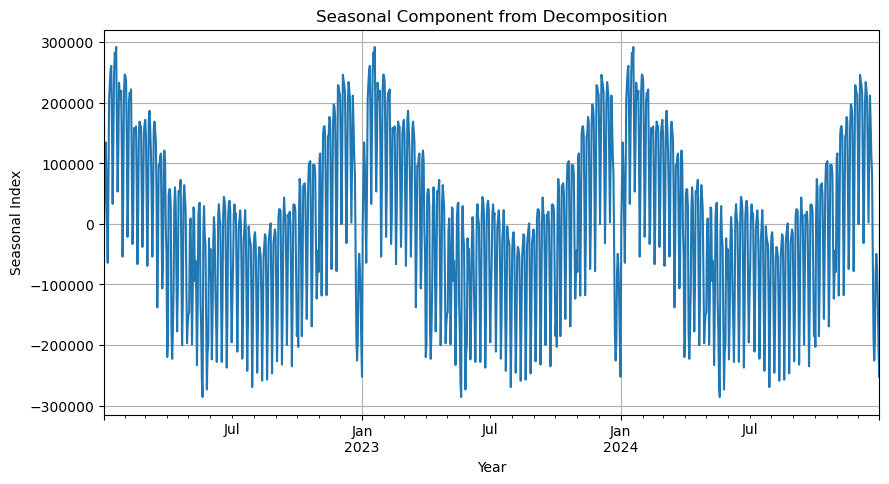

In [112]:
# Plot seasonal components for verification
plt.figure(figsize=(10, 5))
result.seasonal.plot(title="Seasonal Component from Decomposition")
plt.xlabel("Year")
plt.ylabel("Seasonal Index")
plt.grid()
plt.show()

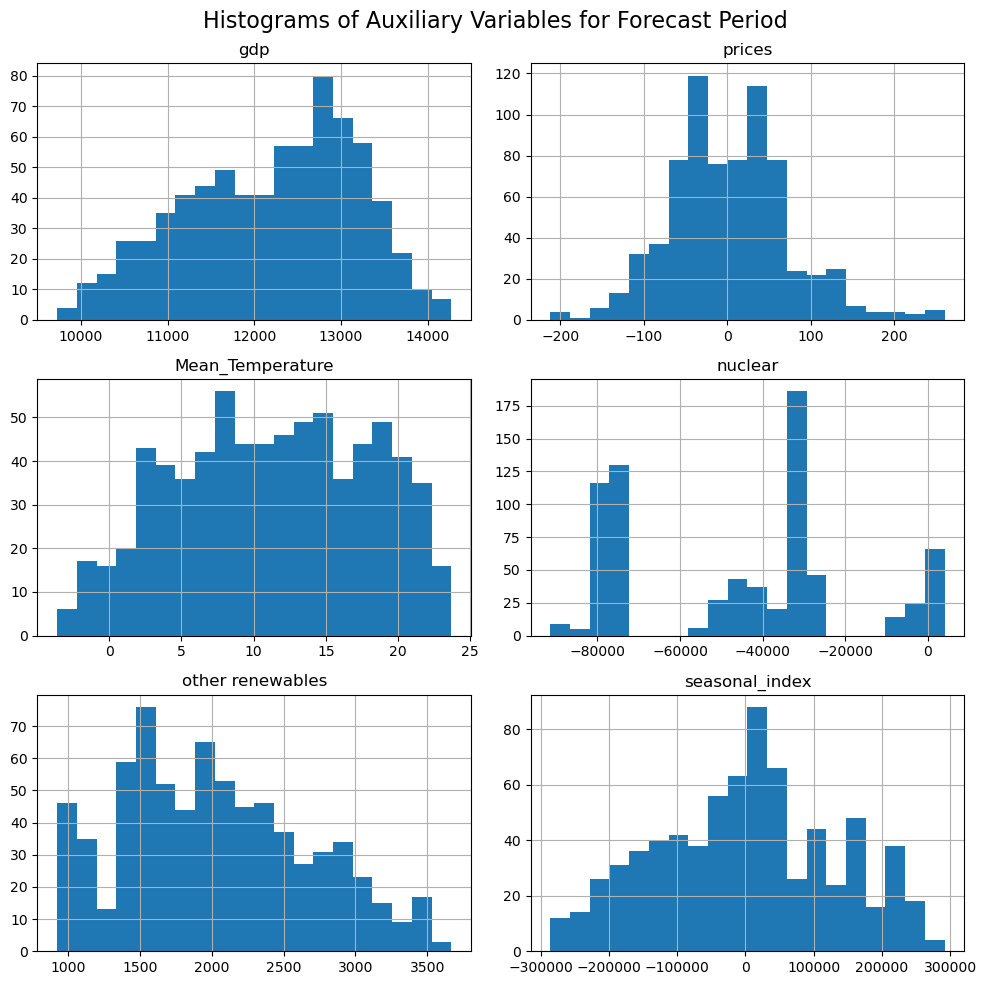

In [113]:
# Plot histograms of auxiliary variables for the forecast period
future_exog.hist(bins=20, figsize=(10, 10))
plt.suptitle("Histograms of Auxiliary Variables for Forecast Period", fontsize=16)
plt.tight_layout()
plt.show()

### Predicting energy consumption  for the next 2 years

In [114]:
# Explicitly set frequency for future_exog index
future_exog.index = pd.date_range(start=future_exog.index.min(), 
                                  periods=len(future_exog), 
                                  freq='D')

In [115]:
# Ensure future_exog contains only the columns used during training
future_exog = future_exog[auxiliary_variables]  # Filter only the original auxiliary variables

In [116]:
# Forecast for the next 2 years (2025–2026)
forecast_steps = future_exog.shape[0]  # Number of days in the forecast period (e.g., 730 for 2025–2026)
forecast_results = final_model.get_forecast(steps=forecast_steps, exog=future_exog)

In [117]:
# Extract forecasted values and confidence intervals
forecasted_mean = forecast_results.predicted_mean
forecasted_ci = forecast_results.conf_int()

In [118]:
# Combine forecast results into a single DataFrame
forecast_df = pd.DataFrame({
    'Forecasted': forecasted_mean,
    'Lower Bound': forecasted_ci.iloc[:, 0],
    'Upper Bound': forecasted_ci.iloc[:, 1]
}, index=future_exog.index)

In [119]:
# Display forecast results
print("Forecast for 2025–2026:")
print(forecast_df.head())

Forecast for 2025–2026:
              Forecasted   Lower Bound   Upper Bound
2025-01-01  1.247166e+06  1.211148e+06  1.283184e+06
2025-01-02  1.248229e+06  1.198008e+06  1.298450e+06
2025-01-03  1.313491e+06  1.256989e+06  1.369993e+06
2025-01-04  1.380220e+06  1.319996e+06  1.440444e+06
2025-01-05  1.338681e+06  1.275203e+06  1.402160e+06


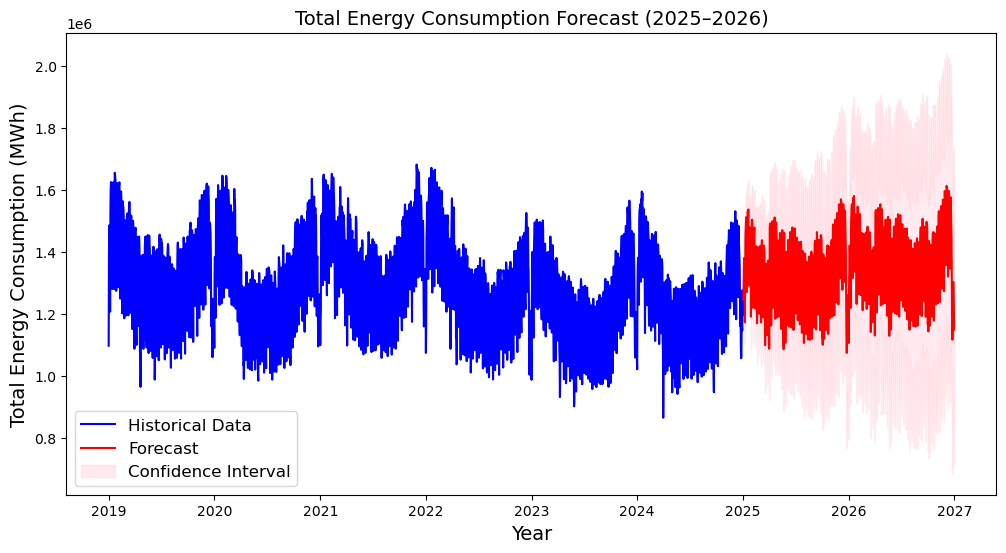

In [127]:
# Plot the forecast
plt.figure(figsize=(12, 6))
plt.plot(data[target_variable], label='Historical Data', color='blue')
plt.plot(forecasted_mean, label='Forecast', color='red')
plt.fill_between(forecast_df.index, forecast_df['Lower Bound'], forecast_df['Upper Bound'], color='pink', alpha=0.3, label='Confidence Interval')
plt.title('Total Energy Consumption Forecast (2025–2026)', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Total Energy Consumption (MWh)', fontsize=14)
plt.legend(loc="lower left", fontsize=12)
#plt.grid()
plt.savefig("plots_energy/sarimax_energy_final_forecast.png", bbox_inches='tight')
plt.show()

In [121]:
# Summarize Forecast Results
forecast_summary = forecast_df.describe()

In [122]:
# Print the key statistics
print("Summary Statistics for Forecasted energy consumption (2025–2026):")
print(forecast_summary)

Summary Statistics for Forecasted energy consumption (2025–2026):
         Forecasted   Lower Bound   Upper Bound
count  7.300000e+02  7.300000e+02  7.300000e+02
mean   1.366287e+06  1.070923e+06  1.661650e+06
std    1.186826e+05  1.418207e+05  1.636376e+05
min    1.073869e+06  6.841007e+05  1.242927e+06
25%    1.273673e+06  9.757821e+05  1.550815e+06
50%    1.385402e+06  1.079512e+06  1.662208e+06
75%    1.459641e+06  1.171492e+06  1.795782e+06
max    1.612874e+06  1.441867e+06  2.039659e+06


In [123]:
# Display summary statistics for confidence intervals
ci_summary = forecast_df[['Lower Bound', 'Upper Bound']].describe()
print("\nSummary of Confidence Intervals:")
print(ci_summary)


Summary of Confidence Intervals:
        Lower Bound   Upper Bound
count  7.300000e+02  7.300000e+02
mean   1.070923e+06  1.661650e+06
std    1.418207e+05  1.636376e+05
min    6.841007e+05  1.242927e+06
25%    9.757821e+05  1.550815e+06
50%    1.079512e+06  1.662208e+06
75%    1.171492e+06  1.795782e+06
max    1.441867e+06  2.039659e+06


In [165]:
# Save forecast results to CSV
forecast_df.to_csv("Total Energy Consumption Forecast 2025_2026.csv", index=True)
print("Forecast results saved to 'Total Energy Consumption Forecast 2025_2026.csv'")

Forecast results saved to 'Total Energy Consumption Forecast 2025_2026.csv'
